## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Payton Gergen

**Date:** 10/12/26

### Question 1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

import warnings
warnings.simplefilter("ignore")

#### Part 1

In [3]:
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#### Part 2

Text(0.5, 1.0, 'noise = 0.125')

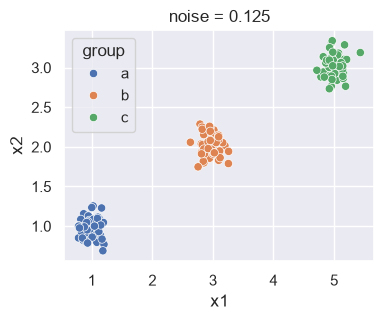

In [4]:
sns.set_theme(rc={'figure.figsize':(4,3)})

sns.scatterplot(df0_125, x = "x1", y = "x2", hue = "group").set_title("noise = 0.125")

Text(0.5, 1.0, 'noise = 0.25')

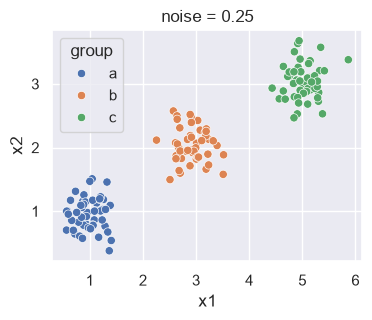

In [5]:
sns.scatterplot(df0_25, x = "x1", y = "x2", hue = "group").set_title("noise = 0.25")

Text(0.5, 1.0, 'noise = 0.5')

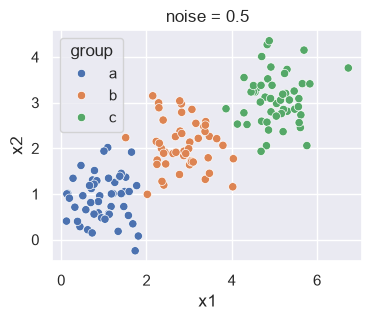

In [6]:
sns.scatterplot(df0_5, x = "x1", y = "x2", hue = "group").set_title("noise = 0.5")

Text(0.5, 1.0, 'noise = 1.0')

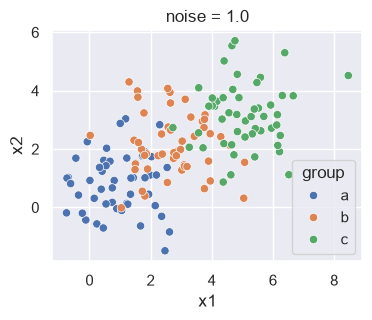

In [7]:
sns.scatterplot(df1_0, x = "x1", y = "x2", hue = "group").set_title("noise = 1.0")

Text(0.5, 1.0, 'noise = 2.0')

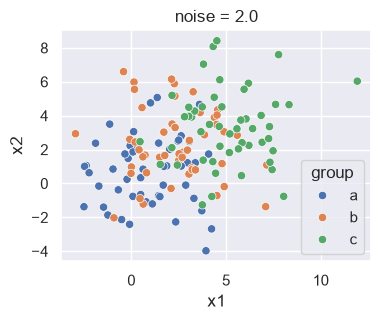

In [8]:
sns.scatterplot(df2_0, x = "x1", y = "x2", hue = "group").set_title("noise = 2.0")

As the noise increases from 0.125 to 2.0, the visual distinctness of the clusters decreases.

#### Part 3

In [9]:
def scree_plot(df):
    features = ["x1", "x2"]
    unscaled = df.loc[:, features]
    X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())

    ks = np.arange(1, 11)
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
        for k in ks
    ]
    plt.plot(ks, SSE)
    plt.title("Scree Plot")
    plt.xlabel("k")
    plt.ylabel("SSE")

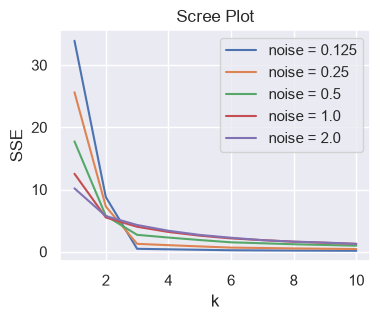

In [10]:
scree_plot(df0_125)
scree_plot(df0_25)
scree_plot(df0_5)
scree_plot(df1_0)
scree_plot(df2_0)
plt.legend(labels = ["noise = 0.125", "noise = 0.25", "noise = 0.5", "noise = 1.0", "noise = 2.0"])

At low levels of noise (0.125 and 0.5), the elbow of the scree plot is clearly at 3. As the noise increases, the elbow becomes less clear. At noise = 0.5, the elbow appears to be between 2 and 3. At noise = 1.0 and 2.0, there is not a clear elbow. Thus, a lower noise level improves the ability to definitevely select k.

#### Part 4

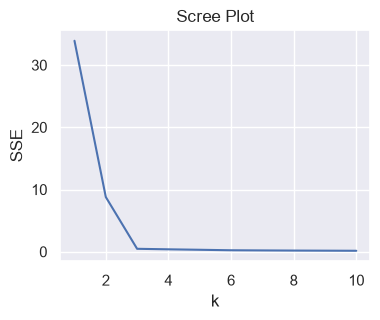

In [11]:
scree_plot(df0_125)

The elbow, as seen above at k=3 for noise = 0.125, demonstrates where the SSE is minimized at the minimum number of groups k. At values of k below 3, the SSE is much larger because points that should not belong to the same group are grouped together. At values of k above 3, the SSE does not significantly decrease compared to k=3 because adding additional groups does not add additional information about the clustering of points.

### Question 2

#### Part 1

In [12]:
df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna()
df.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


#### Part 2

In [13]:
def min_max_scale(c):
    min_c = np.repeat(min(c), len(c))
    max_c = np.repeat(max(c), len(c))
    scaled_c = (c - min_c) / (max_c - min_c)
    return scaled_c

In [14]:
df["Scaled Spending (2020 USD)"] = min_max_scale(df["Spending (2020 USD)"])
df["Scaled Spending per Capita"] = min_max_scale(df["Spending per Capita"])
df.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0.000348,0.002620
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,0.000230,0.025615
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,0.012461,0.087630
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0.001265,0.011767
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,0.003626,0.024627


Text(0, 0.5, 'SSE')

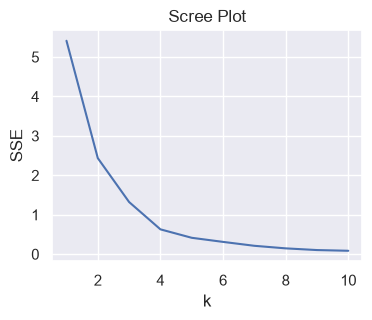

In [15]:
X = df.loc[:, ["Scaled Spending (2020 USD)", "Scaled Spending per Capita"]]

k = np.arange(1,11)
SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
        for k in k
    ]
plt.plot(k, SSE)
plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")

k = 4 is the optimal number of groups.

In [16]:
model = KMeans(n_clusters = 4, n_init = "auto", random_state=0).fit(X)
df["Cluster Part 2"] = model.labels_

<Axes: xlabel='Spending (2020 USD)', ylabel='Spending per Capita'>

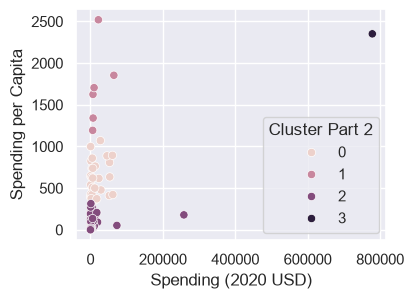

In [17]:
sns.scatterplot(df, x = "Spending (2020 USD)", y = "Spending per Capita", hue = "Cluster Part 2")

In [18]:
df.groupby("Cluster Part 2").describe()

index                                                    \
                count         mean          std     min     25%     50%   
Cluster Part 2                                                            
0                30.0  2782.600000  1664.320688   236.0  1494.0  2769.0   
1                 6.0  3783.333333   843.766476  2582.0  3194.0  4027.0   
2               111.0  2768.540541  1665.488123    32.0  1205.0  2752.0   
3                 1.0  5540.000000          NaN  5540.0  5540.0  5540.0   

                                 Year          ... Scaled Spending (2020 USD)  \
                   75%     max  count    mean  ...                        75%   
Cluster Part 2                                 ...                              
0               4307.5  5506.0   30.0  2020.0  ...                   0.033772   
1               4375.5  4656.0    6.0  2020.0  ...                   0.024215   
2               4112.0  5880.0  111.0  2020.0  ...                   0.002940   
3               5540.0  5540.0    1.0  2020.0  ...                   1.000000   

                         Scaled Spending per Capita                      \
                     max                      count      mean       std   
Cluster Part 2                                                            
0               0.079271                       30.0  0.240850  0.082121   
1               0.082927                        6.0  0.677089  0.185083   
2               0.331409                      111.0  0.031542  0.033138   
3               1.000000                        1.0  0.933024       NaN   

                                                                  
                     min       25%       50%       75%       max  
Cluster Part 2                                                    
0               0.143616  0.167325  0.229550  0.300319  0.424651  
1               0.473454  0.560161  0.660709  0.720941  1.000000  
2               0.000000  0.005675  0.018445  0.049530  0.124462  
3               0.933024  0.933024  0.933024  0.933024  0.933024  

[4 rows x 64 columns]

In [19]:
df[df["Cluster Part 2"] == 0]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2
236,236,2020,Australia,27300.894701,0.020118,0.044978,1070.623322,0.035063,0.424651,0
270,270,2020,Austria,3601.618603,0.008330,0.014533,399.913236,0.004616,0.158477,0
338,338,2020,Bahrain,1404.787234,0.040744,0.114776,825.374403,0.001794,0.327323,0
440,440,2020,Belgium,5442.835974,0.010451,0.017648,469.614838,0.006981,0.186138,0
678,678,2020,Brunei,436.548223,0.040809,0.109474,998.966186,0.000550,0.396213,0
882,882,2020,Canada,23281.319911,0.014159,0.026804,616.854430,0.029899,0.244571,0
1324,1324,2020,Cyprus,483.415023,0.020535,0.043645,400.509547,0.000610,0.158714,0
1426,1426,2020,Denmark,4980.428135,0.013982,0.026010,859.880548,0.006387,0.341017,0
1698,1698,2020,Estonia,718.112390,0.023638,0.051496,541.154778,0.000911,0.214529,0
1834,1834,2020,Finland,4087.541320,0.015305,0.026642,737.690186,0.005240,0.292525,0


In [20]:
df[df["Cluster Part 2"] == 1]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2
2582,2582,2020,Israel,21816.569767,0.053553,0.116052,2520.398541,0.028017,1.000000,1
2922,2922,2020,Kuwait,6941.042345,0.064961,0.097882,1625.156250,0.008906,0.644720,1
4010,4010,2020,Norway,7269.880030,0.020060,0.035207,1341.058851,0.009329,0.531974,1
4044,4044,2020,Oman,6095.708713,0.098470,0.180654,1193.598730,0.007820,0.473454,1
4486,4486,2020,Saudi Arabia,64558.400000,0.092211,0.225050,1854.380422,0.082927,0.735688,1
4656,4656,2020,Singapore,9978.571429,0.029429,0.110489,1705.738706,0.012808,0.676699,1


In [21]:
df[df["Cluster Part 2"] == 2]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0.000348,0.002620,2
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,0.000230,0.025615,2
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,0.012461,0.087630,2
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0.001265,0.011767,2
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,0.003626,0.024627,2
...,...,...,...,...,...,...,...,...,...,...
5404,5404,2020,Uganda,984.759732,0.025971,0.121301,21.529038,0.001254,0.008314,2
5438,5438,2020,Ukraine,5924.200880,0.038118,0.082884,135.459845,0.007600,0.053528,2
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312,0.001391,0.124462,2
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514,0.000261,0.004349,2


In [22]:
df[df["Cluster Part 2"] == 3]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,1.0,0.933024,3


Cluster 1 includes a lot of countries in Europe, and the countries in this group have a relatively moderate spending per capita. Cluster 2 has very high spending per capita. Cluster 3 - the largest group - has low spending per capita, and many of these nations are poorer. The United States is in a distinct cluster with by far the highest military spending amount.

#### Part 3

In [23]:
df["Scaled Percent of Government Spending"] = min_max_scale(df["Percent of Government Spending"])
df["Scaled Percent of GDP"] = min_max_scale(df["Percent of GDP"])
df.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2,Scaled Percent of Government Spending,Scaled Percent of GDP
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0.000348,0.002620,2,0.150377,0.137524
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,0.000230,0.025615,2,0.110877,0.127303
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,0.012461,0.087630,2,0.566960,0.676168
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0.001265,0.011767,2,0.233882,0.146191
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,0.003626,0.024627,2,0.041498,0.073306


Text(0, 0.5, 'SSE')

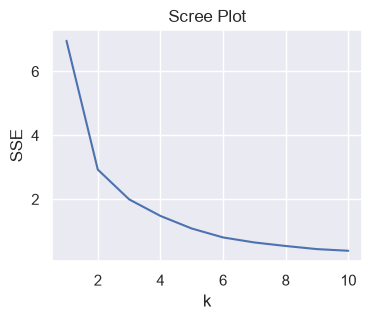

In [24]:
X = df.loc[:, ["Scaled Percent of Government Spending", "Scaled Percent of GDP"]]

k = np.arange(1,11)
SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
        for k in k
    ]
plt.plot(k, SSE)
plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")

k = 2 is the optimal number of groups.

In [25]:
model = KMeans(n_clusters = 2, n_init = "auto", random_state=0).fit(X)
df["Cluster Part 3"] = model.labels_

<Axes: xlabel='Percent of Government Spending', ylabel='Percent of GDP'>

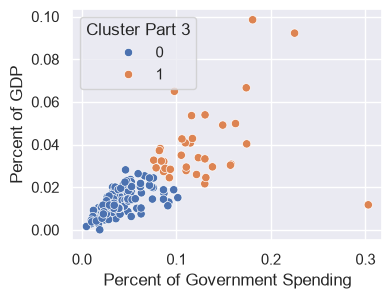

In [26]:
sns.scatterplot(df, x = "Percent of Government Spending", y = "Percent of GDP", hue = "Cluster Part 3")

In [27]:
df.groupby("Cluster Part 3").describe()

index                                                   \
                count         mean          std    min     25%     50%   
Cluster Part 3                                                           
0               113.0  2863.628319  1621.311342   32.0  1562.0  2888.0   
1                35.0  2726.742857  1777.194225  100.0   899.0  2854.0   

                                 Year          ...  \
                   75%     max  count    mean  ...   
Cluster Part 3                                 ...   
0               4248.0  5880.0  113.0  2020.0  ...   
1               4061.0  5540.0   35.0  2020.0  ...   

               Scaled Percent of Government Spending            \
                                                 75%       max   
Cluster Part 3                                                   
0                                           0.156306  0.324036   
1                                           0.465191  1.000000   

               Scaled Percent of GDP                                          \
                               count      mean       std       min       25%   
Cluster Part 3                                                                 
0                              113.0  0.136435  0.060622  0.000000  0.092397   
1                               35.0  0.400125  0.184716  0.118758  0.293731   

                                              
                     50%       75%       max  
Cluster Part 3                                
0               0.137951  0.180619  0.285294  
1               0.337621  0.433550  1.000000  

[2 rows x 88 columns]

In [28]:
df[df["Cluster Part 3"] == 0]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2,Scaled Percent of Government Spending,Scaled Percent of GDP,Cluster Part 3
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0.000348,0.002620,2,0.150377,0.137524,0
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,0.000230,0.025615,2,0.110877,0.127303,0
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0.001265,0.011767,2,0.233882,0.146191,0
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,0.003626,0.024627,2,0.041498,0.073306,0
236,236,2020,Australia,27300.894701,0.020118,0.044978,1070.623322,0.035063,0.424651,0,0.134443,0.203867,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5336,5336,2020,Turkey,17478.413685,0.024322,0.071553,207.239992,0.022444,0.082014,2,0.223581,0.246586,0
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388,0.077938,0.354469,0,0.136627,0.227137,0
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312,0.001391,0.124462,2,0.191815,0.220723,0
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514,0.000261,0.004349,2,0.098495,0.116731,0


In [29]:
df[df["Cluster Part 3"] == 1]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Scaled Spending (2020 USD),Scaled Spending per Capita,Cluster Part 2,Scaled Percent of Government Spending,Scaled Percent of GDP,Cluster Part 3
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,0.012461,0.087630,2,0.566960,0.676168,1
202,202,2020,Armenia,633.960400,0.049827,0.162572,213.958961,0.000803,0.084680,2,0.528881,0.505743,1
304,304,2020,Azerbaijan,2237.764706,0.053905,0.130339,220.708621,0.002864,0.087359,2,0.420764,0.547175,1
338,338,2020,Bahrain,1404.787234,0.040744,0.114776,825.374403,0.001794,0.327323,0,0.368563,0.413447,1
406,406,2020,Belarus,707.418033,0.011742,0.303027,74.866974,0.000898,0.029481,2,1.000000,0.118758,1
610,610,2020,Botswana,499.027480,0.032024,0.086676,212.171547,0.000630,0.083971,2,0.274308,0.324845,1
678,678,2020,Brunei,436.548223,0.040809,0.109474,998.966186,0.000550,0.396213,0,0.350780,0.414106,1
746,746,2020,Burkina Faso,382.464677,0.027340,0.086497,18.297119,0.000480,0.007031,2,0.273710,0.277246,1
814,814,2020,Cambodia,646.974133,0.024455,0.092572,38.696940,0.000820,0.015127,2,0.294085,0.247933,1
984,984,2020,Chad,322.866526,0.030784,0.157918,19.655822,0.000404,0.007570,2,0.513270,0.312245,1


Here, there are fewer groups identified. The variables are also more linearly related.

#### Part 4

Text(0, 0.5, 'SSE')

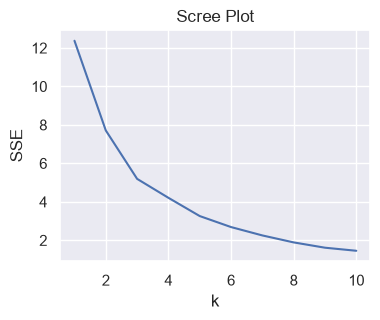

In [30]:
X = df.loc[:, ["Scaled Spending (2020 USD)", "Scaled Spending per Capita", "Scaled Percent of Government Spending", "Scaled Percent of GDP"]]

k = np.arange(1,11)
SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
        for k in k
    ]
plt.plot(k, SSE)
plt.title("Scree Plot")
plt.xlabel("k")
plt.ylabel("SSE")

In [39]:
model = KMeans(n_clusters = 3, n_init = "auto", random_state=0).fit(X)
df["Cluster Part 4"] = model.labels_

<Axes: xlabel='Spending (2020 USD)', ylabel='Spending per Capita'>

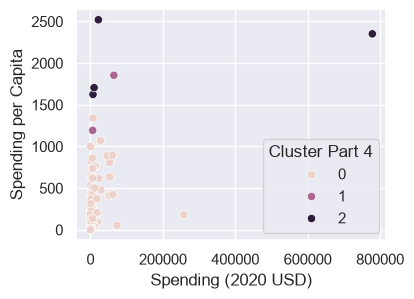

In [40]:
sns.scatterplot(df, x = "Spending (2020 USD)", y = "Spending per Capita", hue = "Cluster Part 4")

<Axes: xlabel='Percent of Government Spending', ylabel='Percent of GDP'>

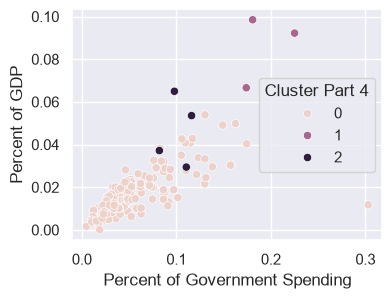

In [41]:
sns.scatterplot(df, x = "Percent of Government Spending", y = "Percent of GDP", hue = "Cluster Part 4")

The majority of the data fell in one group. The other two groups had high or very high values for most of the variables.

#### Part 5

The k-means clustering algorithm identifies nations that have abnormally high spending by a variety of metrics.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [12]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]